In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, pearsonr, probplot

pd.set_option('display.float_format', '{:.2f}'.format)

df = pd.read_csv("../lab-eda-bivariate/data/amz_uk_price_prediction_dataset.csv")

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.70,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.70,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.60,1881,17.99,False,0,Hi-Fi Speakers


In [7]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


# Part 1: Analyzing Best-Seller Trends Across Product Categories

- Objective: Understand the relationship between product categories and their best-seller status.

- Crosstab Analysis: Create a crosstab between the product category and the isBestSeller status.

Are there categories where being a best-seller is more prevalent? 

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [33]:
crosstab_cat_bs = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_cat_bs.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [35]:
best_seller_prop = (
    crosstab_cat_bs[True] / crosstab_cat_bs.sum(axis=1)
).sort_values(ascending=False)*100

best_seller_prop.head(10)

category
Grocery                          5.81
Smart Home Security & Lighting   5.77
Health & Personal Care           5.77
Mobile Phone Accessories         4.25
Power & Hand Tools               3.53
Billiard, Snooker & Pool         3.21
Pet Supplies                     3.02
Home Brewing & Wine Making       2.85
Wind Instruments                 2.80
Mirrors                          2.80
dtype: float64

**Yes, there are categories where being a best-seller is more prevalent. Grocery and, Home Security and Health/Beauty-related categories stand out the most.**

- Statistical Tests: Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

In [36]:
chi2, p, dof, expected = chi2_contingency(crosstab_cat_bs)

print("Chi-square statistic:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295


Since the p-value is effectively 0, we reject the null hypothesis of independence (that best-sellers are randomly spread across all categories).

**Conclusion: category DOES affect whether a product is a best-seller.**

- Compute Cramér's V to understand the strength of association between best-seller status and category.

In [37]:
n = crosstab_cat_bs.sum().sum()
min_dim = min(crosstab_cat_bs.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))
print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


**The relationship exists and is statistically significant, but the strength of association is small. Category matters… just not that much.**

- Visualizations: Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

In [47]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

# Rename boolean columns to strings
crosstab = crosstab.rename(columns={False: 'not_best_seller', True: 'best_seller'})

# If one of the columns is missing, create it
for col in ['not_best_seller', 'best_seller']:
    if col not in crosstab.columns:
        crosstab[col] = 0

# Add total and proportion
crosstab['total'] = crosstab['not_best_seller'] + crosstab['best_seller']
crosstab['prop_best_seller'] = crosstab['best_seller'] / crosstab['total']

# Rank categories by proportion of best-sellers
top_categories = crosstab.sort_values('prop_best_seller', ascending=False).head(15)

top_categories.head()

isBestSeller,not_best_seller,best_seller,total,prop_best_seller
category,,,,
Grocery,9008,556,9564,0.06
Smart Home Security & Lighting,98,6,104,0.06
Health & Personal Care,9017,552,9569,0.06
Mobile Phone Accessories,248,11,259,0.04
Power & Hand Tools,8353,306,8659,0.04


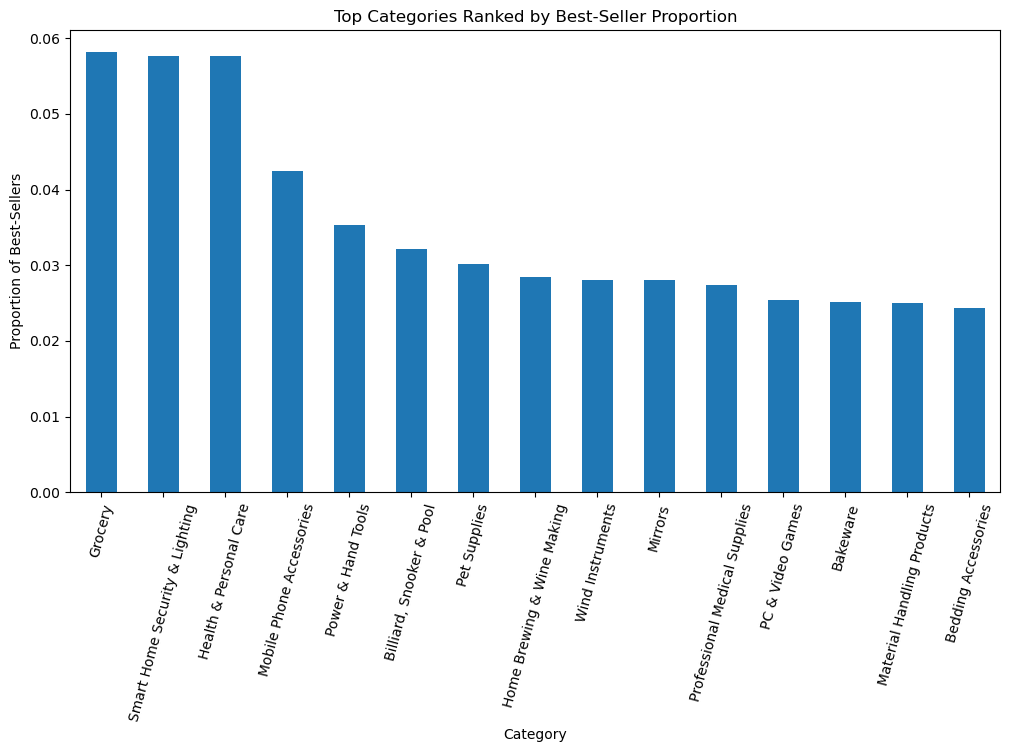

In [49]:
top_categories['prop_best_seller'].plot(kind='bar', figsize=(12,6))

plt.title("Top Categories Ranked by Best-Seller Proportion")
plt.xlabel("Category")
plt.ylabel("Proportion of Best-Sellers")
plt.xticks(rotation=75)
plt.show()

# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

- Objective: Investigate how different product categories influence product prices.
- Preliminary Step: Remove outliers in product prices.

For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.

Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.

In [63]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[
    (df['price'] >= lower_bound) & (df['price'] <= upper_bound)
].copy()

print("Original shape:", df.shape)
print("Without outliers:", df_no_outliers.shape)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Original shape: (2443651, 9)
Without outliers: (2115963, 9)
Lower bound: -44.01
Upper bound: 99.99000000000001


- Violin Plots: Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization. Which product category tends to have the highest median price? Don't filter here by top categories.

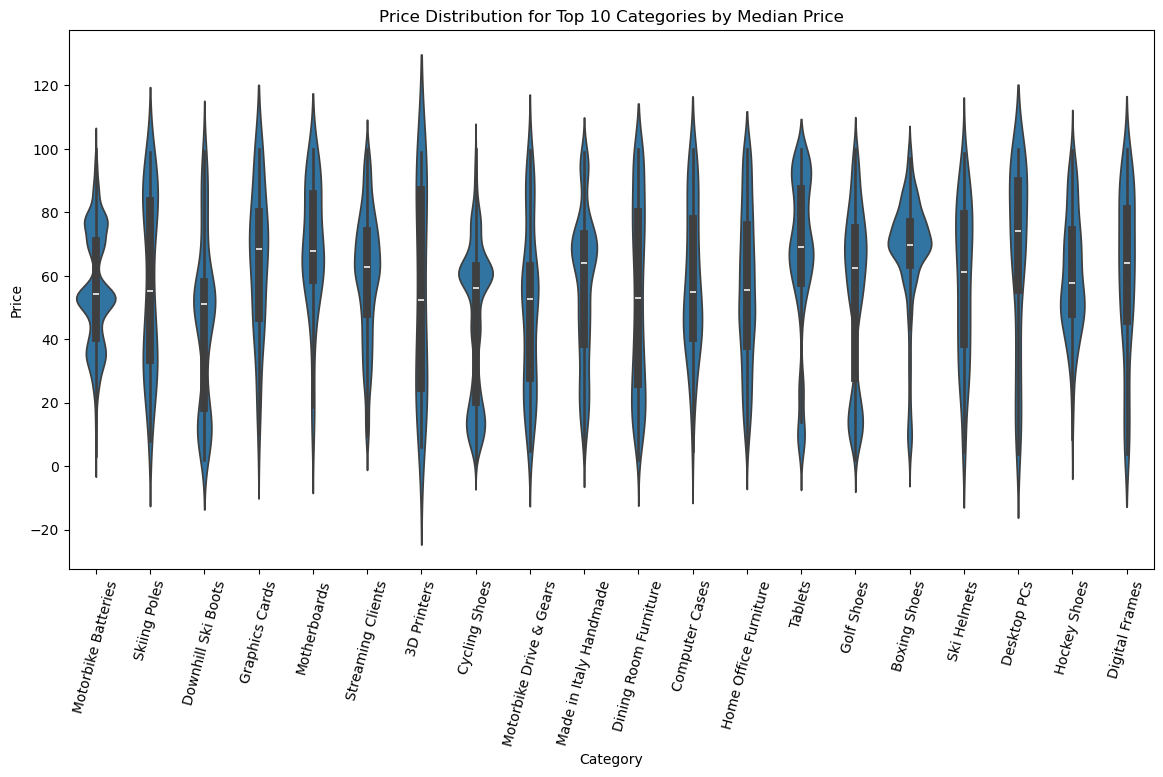

In [68]:
top_categories_price = (
    df_no_outliers.groupby('category')['price']
    .median()
    .sort_values(ascending=False)
    .head(20)
    .index
)
plt.figure(figsize=(14,7))

sns.violinplot(
    data=df_no_outliers[df_no_outliers['category'].isin(top_categories_price)],
    x='category',
    y='price'
)

plt.title("Price Distribution for Top 10 Categories by Median Price")
plt.xlabel("Category")
plt.ylabel("Price")
plt.xticks(rotation=75)
plt.show()

**Desktop PCs has the highest median price after outlier removal.**

- Bar Charts: Create a bar chart comparing the average price of products for the top 10 product categories (based on count). Which product category commands the highest average price? Don't filter here by top categories.

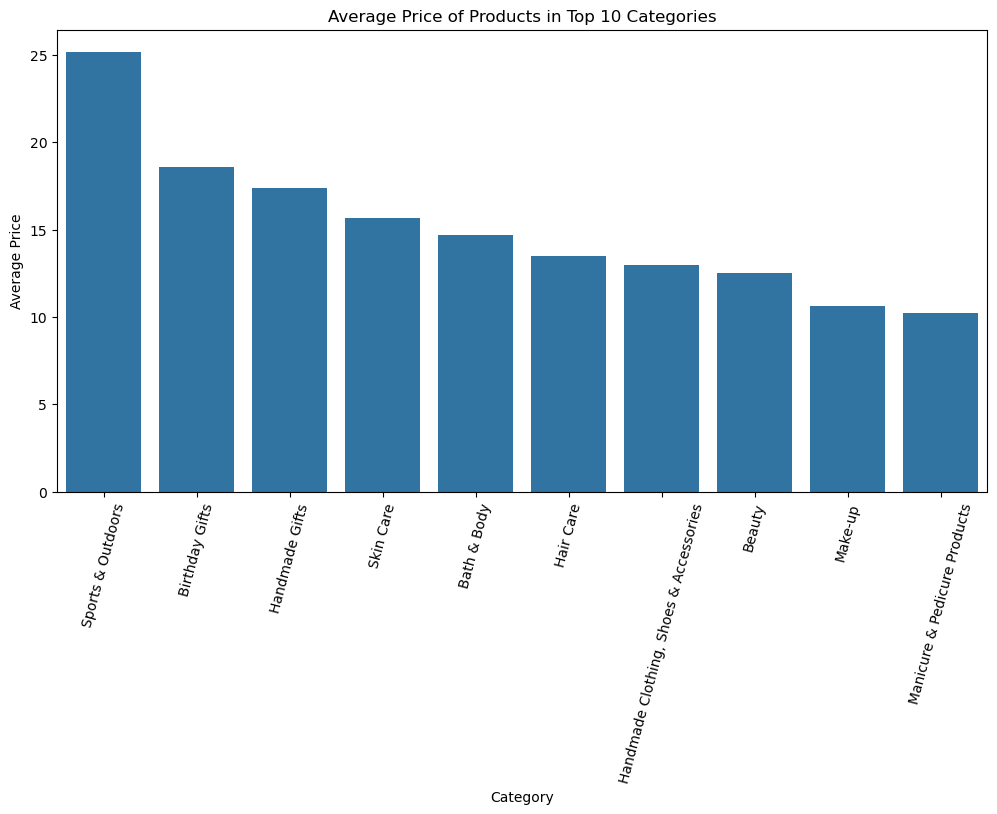

In [69]:
top_10_categories = df_no_outliers['category'].value_counts().head(10).index

avg_price_top10 = (
    df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))
sns.barplot(x=avg_price_top10.index, y=avg_price_top10.values)
plt.xticks(rotation=75)
plt.title("Average Price of Products in Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Average Price")
plt.show()

In [70]:
category_mean_price = (
    df_no_outliers.groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

category_mean_price.head(10)

category
Motherboards        68.77
Boxing Shoes        67.42
Desktop PCs         66.92
Tablets             66.55
Graphics Cards      65.10
Digital Frames      60.75
Streaming Clients   60.24
Hockey Shoes        60.09
Computer Cases      58.34
Skiing Poles        57.87
Name: price, dtype: float64

**After removing outliers, Motherboards has the highest average price.**

- Box Plots: Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

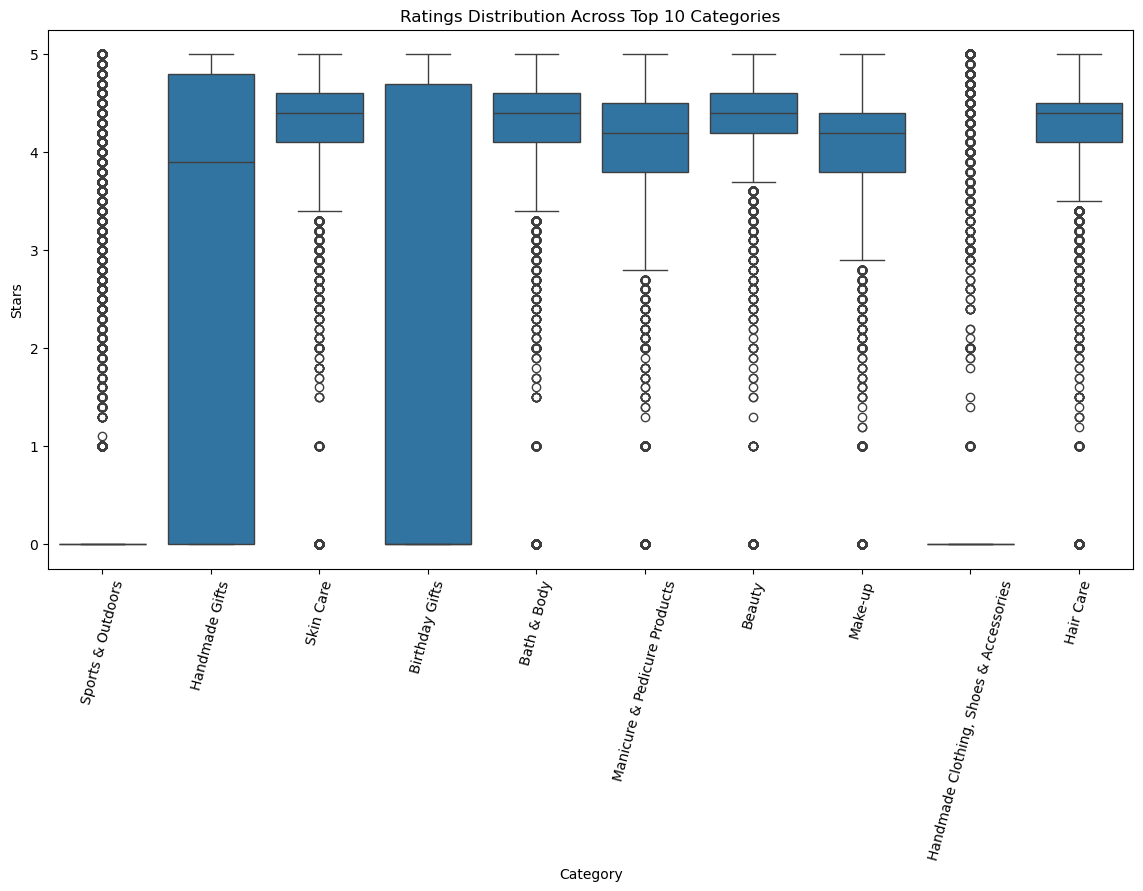

In [71]:
top_10_categories = df_no_outliers['category'].value_counts().head(10).index

plt.figure(figsize=(14,7))
sns.boxplot(
    data=df_no_outliers[df_no_outliers['category'].isin(top_10_categories)],
    x='category',
    y='stars'
)
plt.xticks(rotation=75)
plt.title("Ratings Distribution Across Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Stars")
plt.show()

In [72]:
category_median_rating = (
    df_no_outliers.groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
)

category_median_rating.head(10)

category
Computer Memory                4.70
Building & Construction Toys   4.60
Office Paper Products          4.60
Luxury Food & Drink            4.60
Kids' Play Figures             4.60
Hobbies                        4.60
Beer, Wine & Spirits           4.60
Laptop Accessories             4.60
Cables & Accessories           4.50
CPUs                           4.50
Name: stars, dtype: float64

**The highest median rating belongs to Computer Memory.**

# Part 3: Investigating the Interplay Between Product Prices and Ratings

- Objective: Analyze how product ratings (stars) correlate with product prices.

- Correlation Coefficients: Calculate the correlation coefficient between price and stars.

Is there a significant correlation between product price and its rating?

In [73]:
corr_price_stars = df_no_outliers['price'].corr(df_no_outliers['stars'])
print("Correlation between price and stars:", corr_price_stars)

Correlation between price and stars: -0.07767299878181352


**More expensive products do not clearly get better ratings.**

- Visualizations: Use a scatter plot to visualize the relationship between product rating and price.

What patterns can you observe? Use a correlation heatmap to visualize correlations between all numerical variables. Examine if product prices typically follow a normal distribution using a QQ plot.

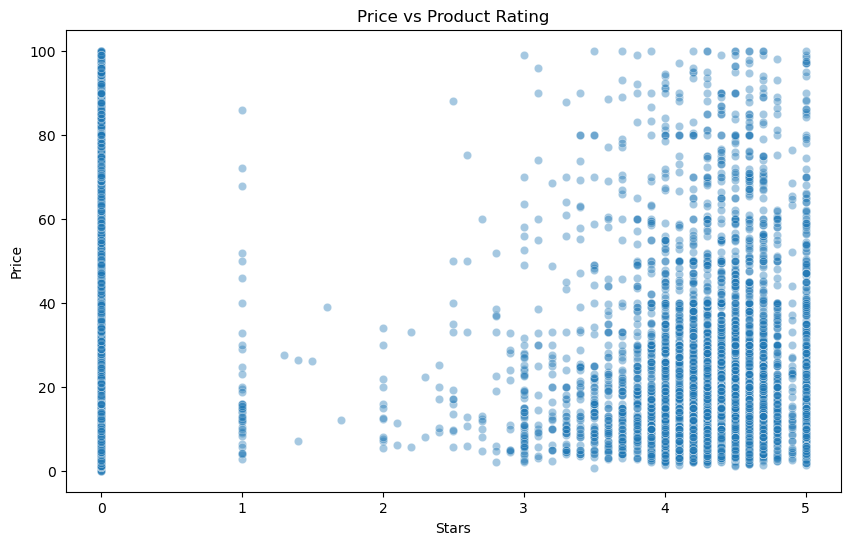

In [74]:
sample_df = df_no_outliers.sample(10000, random_state=42)

plt.figure(figsize=(10,6))
sns.scatterplot(data=sample_df, x='stars', y='price', alpha=0.4)
plt.title("Price vs Product Rating")
plt.xlabel("Stars")
plt.ylabel("Price")
plt.show()

**What I see:**

- lots of products clustered at lower prices
- ratings concentrated around common values
- no strong upward or downward visual trend

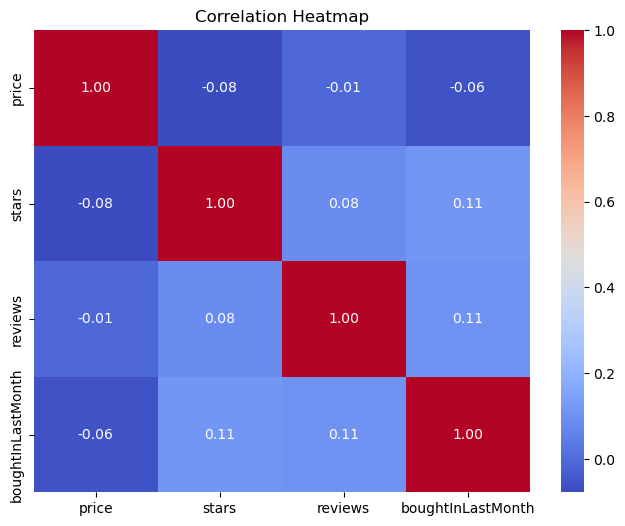

In [75]:
numeric_cols = ['price', 'stars', 'reviews', 'boughtInLastMonth']
corr_matrix = df_no_outliers[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

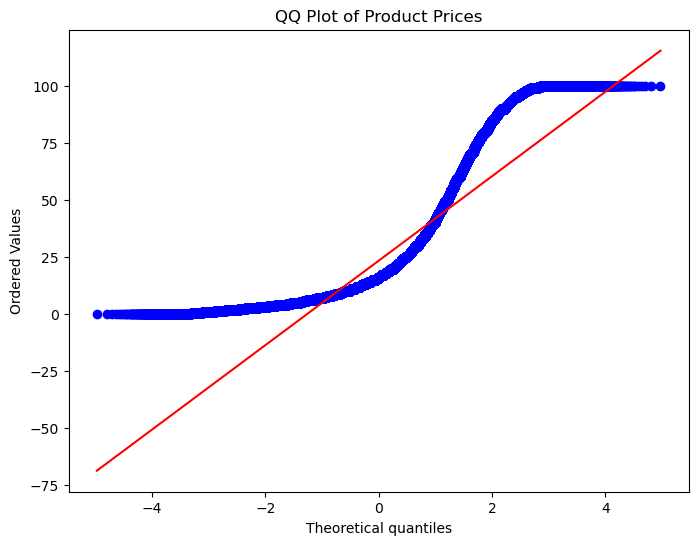

In [76]:
plt.figure(figsize=(8,6))
probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.show()

**Price does not follow a normal distribution.**

# Bonus:

- Do the same analysis without taking out the outliers. What are your insights?

In [77]:
corr_full = df['price'].corr(df['stars'])
print(corr_full)

-0.1249067326214869


**Extreme prices distort the analysis. Removing outliers gives a more realistic view of the typical marketplace.**